# DINGO: recover a galaxy with a known rotation curve

Invent one smooth galaxy, disperse it into R and C, and fit it with the **same rotation-only fitter used on real sources**. Orange dashed lines mark the injected truth.

Use the **grism** kernel and run top to bottom. Only the grism calibration files are needed; no real source images or previous fits are used. This first test has **no PSF and no intrinsic velocity dispersion**. The exponential emission shape generates the data; it is not supplied as a morphology prior to the fit.

In [1]:
from pathlib import Path
import os
import sys
import importlib
import logging
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "dingo").is_dir() else Path("/home/aakavan/kinematics/grism-kinematics")
CALIBRATION_DIR = REPO.parent / "grism_cal"
SAVE_ROOT = REPO / "results" / "simulations"
EXPERIMENT = "disk_200"          # Change this to keep a different experiment
OVERRIDE = True                 # Replace only this named synthetic experiment
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm, simple_simulation as sim, simulation_review as review
sm = importlib.reload(sm)
sim = importlib.reload(sim)
review = importlib.reload(review)
print("Device:", DEVICE)
print("Simulation folder:", SAVE_ROOT / EXPERIMENT)

Device: cuda
Simulation folder: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200


## 1. Choose the true galaxy and generate its images

These are **known input values**, not fitting guesses. The center and radii are zero-based pixels; angles are degrees. `velocity` is the deprojected asymptotic $V_\infty$.

Start with the defaults. To test a nonrotator, change `velocity=0` and use a new experiment name. At zero rotation, orientation and turnover radius can be unconstrained; assess an upper limit on velocity rather than expecting a symmetric error bar around zero. `noise_sigma=0` produces a noiseless-only check and skips fitting/MCMC below. R and C otherwise receive independent Gaussian noise with the stated standard deviation. Changing `seed` makes another noise realization.

Rerunning this generation cell with `OVERRIDE=True` replaces this simulation and its earlier fits. To try another fitting start on the same images, rerun from step 3 instead.

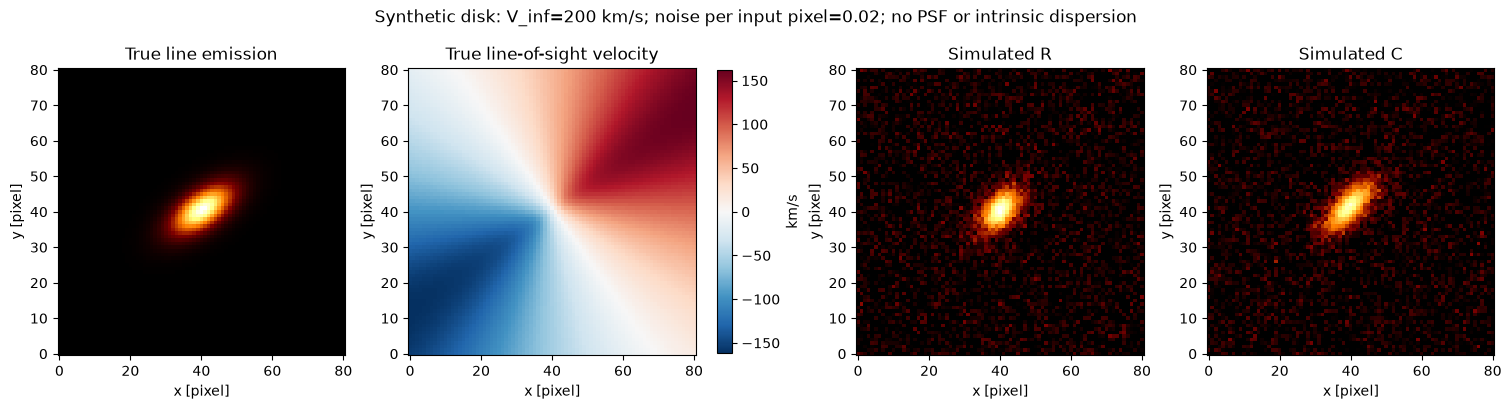

Inputs and truth: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200


In [2]:
mock = sim.make_mock(
    SAVE_ROOT / EXPERIMENT,
    velocity=200.0,
    turnover=5.0,
    inclination=60.0,
    pa=35.0,
    center=(40.3, 40.7),
    effective_radius=6.0,
    peak=1.0,
    noise_sigma=0.02,
    seed=42,
    overwrite=OVERRIDE,
)
fig = review.show_inputs(mock)
display(fig)
plt.close(fig)
print("Inputs and truth:", mock.directory)

## 2. Does the residual prefer the correct velocity?

Only velocity changes here; all other parameters equal their true values. The curves show **extra squared R−C residual above each curve's grid minimum**: lower is better. This is a diagnostic scan, not an error bar or a search used to initialize the fits.

The noiseless panel checks interpolation and the forward/inverse mapping. The noisy panel adds measurement noise. A shifted minimum is a result to investigate. **Initial check of these defaults:** the noiseless curve prefers 150 km/s on this grid, despite an injected 200 km/s. The injected velocity field and scan settings were verified. This exposes a mismatch in the existing generation/rectification setup; recovery is not yet validated.

Noiseless velocity check:   0%|          | 0/41 [00:00<?, ?it/s]

With noise velocity check:   0%|          | 0/41 [00:00<?, ?it/s]

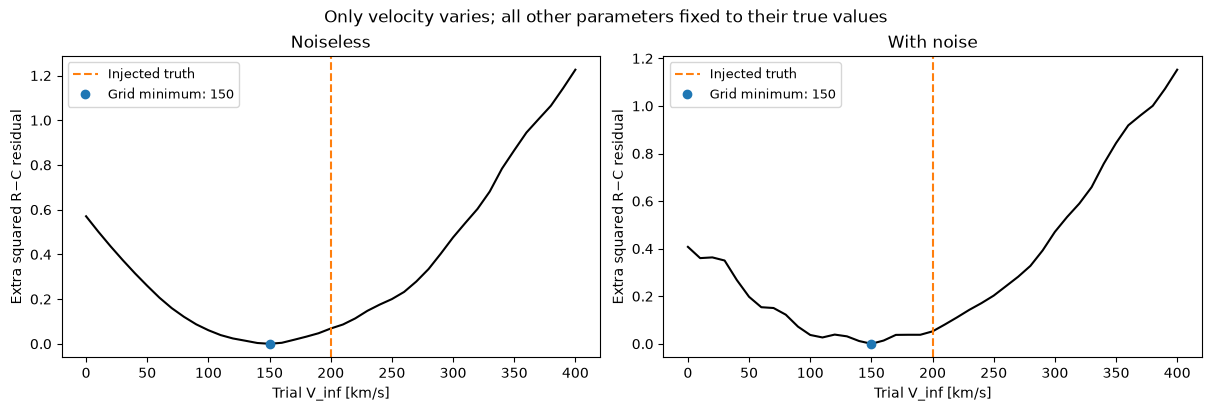

In [3]:
scan, fig = review.scan_velocity(mock, np.arange(0.0, 401.0, 10.0), device=DEVICE)
display(fig)
plt.close(fig)

## 3. Fit from different starting velocities

The center and inclination are fixed to their true values for this first controlled test. **Velocity, turnover radius, orientation, and R registration offsets are fitted.** The starting turnover radius is 3 pixels and orientation is 20°, different from their true values.

These are three independent local optimizations of the same data. Compare their final values and scores; an optimizer finishing does not guarantee recovery. An `optimizer_finished=False` entry means its evaluation budget was exhausted. No MCMC is run in this cell.

In [4]:
runs = {}
if mock.metadata["noise_sigma"] > 0:
    for start in (75.0, 350.0, 800.0):
        run = review.prepare_recovery(
            mock, start_velocity=start, start_turnover=3.0, start_pa=20.0,
            device=DEVICE, overwrite=OVERRIDE,
        )
        sm.fit_local(run, max_evaluations=1000)
        runs[start] = run
    display(review.compare_starts(mock, runs))
else:
    print("Noiseless experiment: inspect the scan; add noise before fitting uncertainties.")

ID9000001: explicit V_inf=75 km/s; fixed i=60 deg.
Saving to /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_75
Fixed: x0=40.3 px, y0=40.7 px, i=60 deg. Excluded from optimization and MCMC; intervals are conditional on these values.


Local fit evaluations:   0%|          | 0/1000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (375 evaluations).
ID9000001: explicit V_inf=350 km/s; fixed i=60 deg.
Saving to /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_350
Fixed: x0=40.3 px, y0=40.7 px, i=60 deg. Excluded from optimization and MCMC; intervals are conditional on these values.


Local fit evaluations:   0%|          | 0/1000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (524 evaluations).
ID9000001: explicit V_inf=800 km/s; fixed i=60 deg.
Saving to /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_800
Fixed: x0=40.3 px, y0=40.7 px, i=60 deg. Excluded from optimization and MCMC; intervals are conditional on these values.


Local fit evaluations:   0%|          | 0/1000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (354 evaluations).


,start_V_inf,fitted_V_inf,true_V_inf,fitted_R_t,true_R_t,fitted_PA_deg,log_posterior,optimizer_finished
0,75.0,105.696943,200.0,3.572579,5.0,38.799230,16157.172251,True
1,350.0,105.962209,200.0,3.567654,5.0,38.648054,16157.210730,True
2,800.0,105.413171,200.0,3.547064,5.0,38.749423,16157.187688,True


## 4. Sample one fit with MCMC

Choose which starting-velocity experiment to sample. This does not automatically select the answer closest to truth. Sampling uses emcee with the PyTorch likelihood on the selected device; progress bars and checkpoints are enabled.

The defaults are a short exploratory run, not a convergence guarantee. Increase `warmup`, `draws`, and `walkers` here when needed. Longer chains cannot repair a shifted noiseless minimum. The known input noise is used in the same fixed-variance likelihood as the real-data notebook; covariance introduced by rectification is still approximate.

In [5]:
MCMC_START = 350.0
RESULT_DIR = None
if runs:
    RESULT_DIR = sm.sample(
        runs[MCMC_START],
        warmup=100,
        draws=200,
        walkers=32,
        seed=42,
        progress="notebook",
    )
    print("Saved fit:", RESULT_DIR)

Warmup:   0%|          | 0/100 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/200 [00:00<?, ?it/s]

The chain is shorter than 50 times the integrated autocorrelation time for 5 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 4;
tau: [11.58454619 13.12415116 11.93559581 11.62213683 12.16516563]


finished: 200 retained steps per walker.
Results: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_350
Saved fit: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_350


## 5. Compare the answer with the truth

The table adds the injected values; the corner and trace plots mark them in orange. The rotation plot compares the full curves at common radii. All retained walkers enter the summaries.

A clean corner plot is useful only if the recovered parameters/curve also agree with truth. Fixed center/inclination uncertainty is absent by design. Repeating different noise realizations is needed to assess error-bar coverage; this single simulation cannot certify it. Pixel dispersion followed by rectification is not exactly reversible, even without noise.

Plots, samples, and `run_info.txt` are inside the selected fit folder. To reopen without rerunning: load the simulation with `sim.load_mock(SAVE_ROOT / EXPERIMENT)`, set `RESULT_DIR` to its saved fit folder, and run this cell.

Status: finished; retained steps/walker: 200; latest segment mean acceptance: 0.225
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Fixed: x0=40.3 px, y0=40.7 px, i=60 deg. These quantities were not sampled; their uncertainty is not included.
Autocorrelation time per parameter: {'velocity.V_rot': 11.584546189050794, 'velocity.R_v': 13.12415115783342, 'velocity.theta_v': 11.935595809628868, 'image.R.dx': 11.622136832574467, 'image.R.dy': 12.165165629968563}
Truth comparisons and plots saved in: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200/fits/9000001/start_350


,truth,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,,
V_inf,200.0,105.474996,2.320328,2.530606,km/s
R_t,5.0,3.610921,0.213125,0.215280,pixel
cutout_PA,35.0,39.344397,1.912423,2.636930,deg
R_x_offset,0.0,0.165278,0.012320,0.016007,pixel
R_y_offset,0.0,0.225504,0.013526,0.013228,pixel


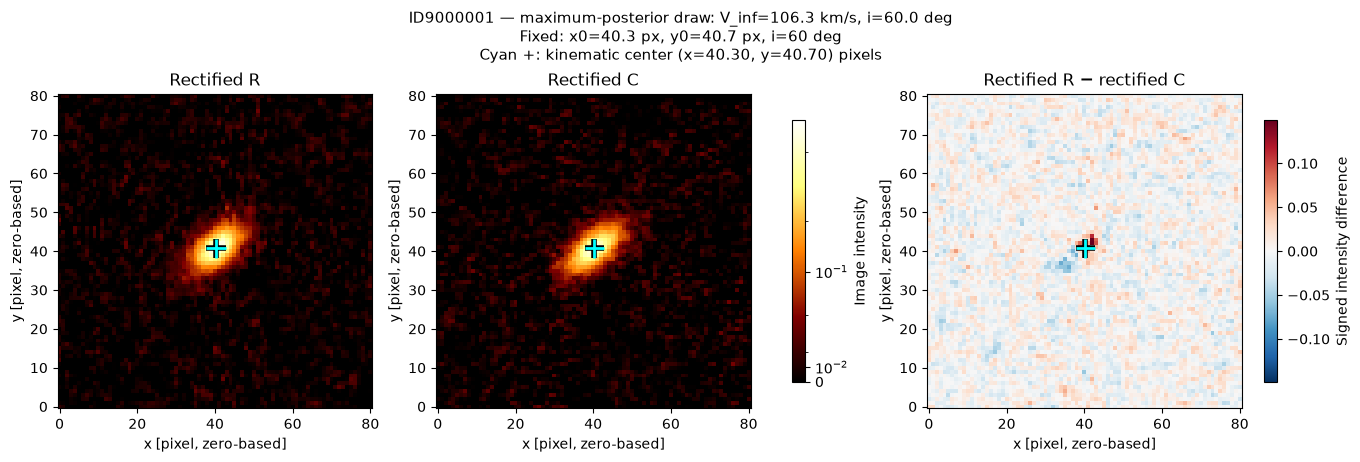

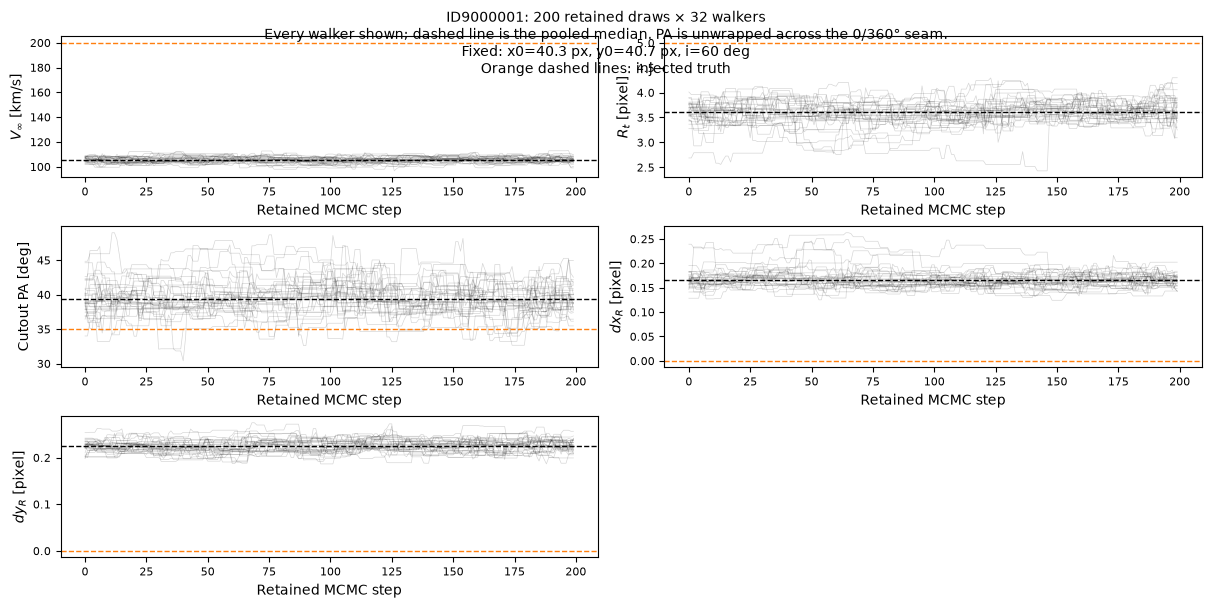

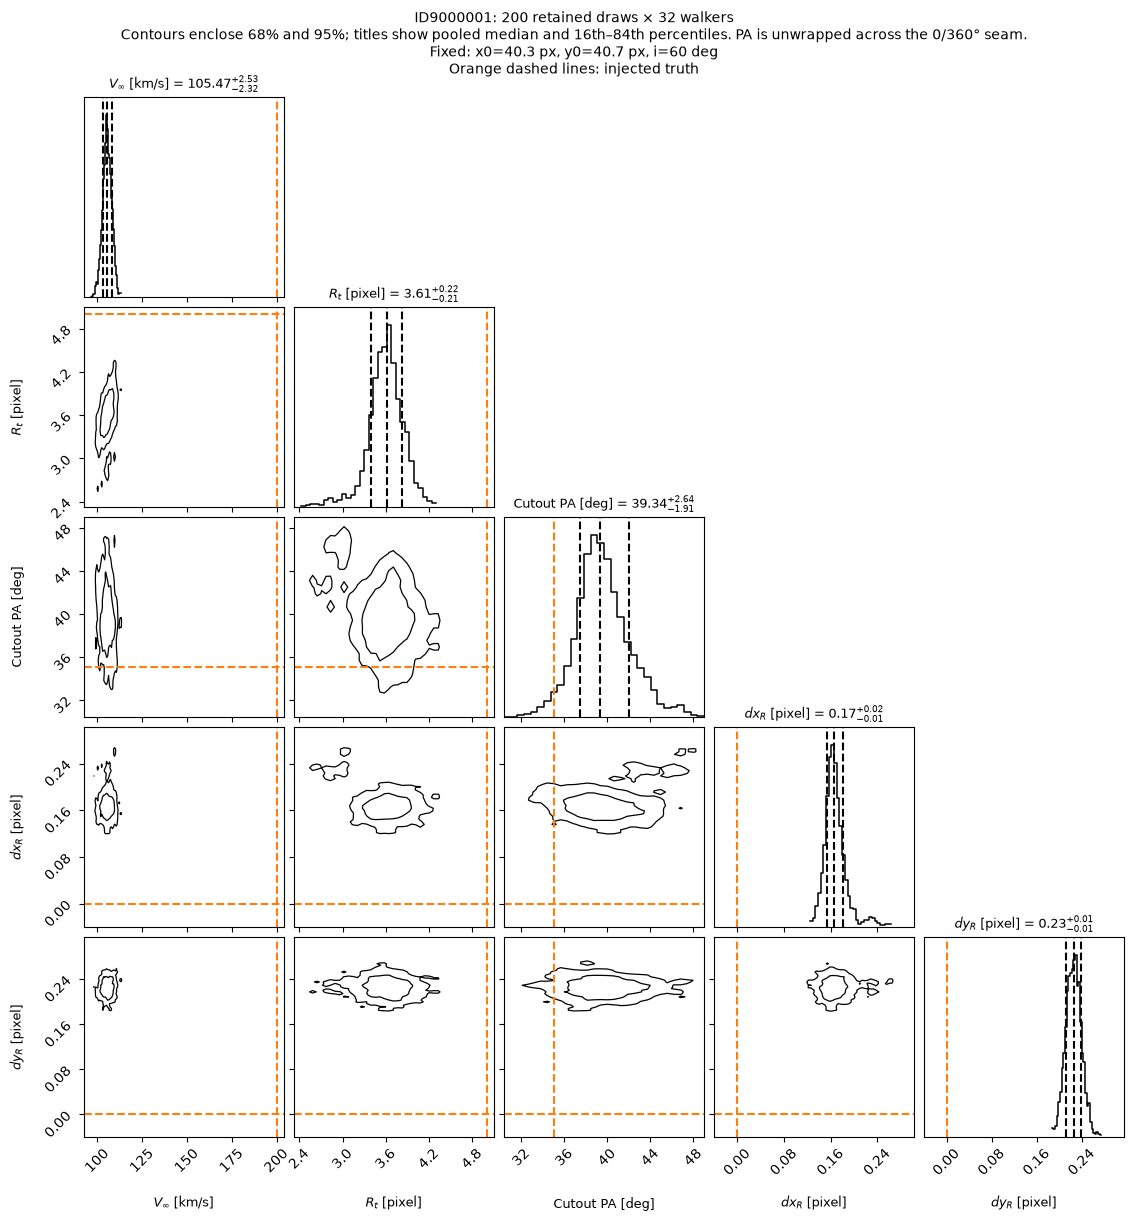

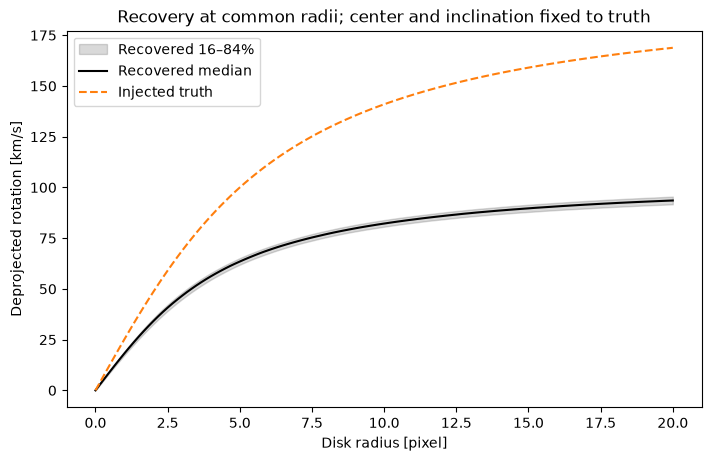

In [6]:
if RESULT_DIR is not None:
    views = review.compare_posterior(mock, RESULT_DIR)
    display(views["summary"])
    for name in ("residuals", "traces", "corner", "rotation_curve"):
        display(views[name])
        plt.close(views[name])
else:
    print("No MCMC results selected; the noiseless velocity scan is saved above.")